# Ward adverse events: choosing a count distribution

The goal is to model how a daily count of adverse events varies with season and
ward occupancy, and to produce an interval around the prediction.

A count response suggests a Poisson model. This study measures what that
assumption costs when it is wrong, which diagnostics detect it, and what can be
reported when the data do not identify a single replacement.

The workflow for counts is: fit a plausible baseline, inspect the feature it misses, compare candidates on out-of-bag risk, and check the selected distribution with PIT values (the probability integral transform: the fitted cumulative distribution evaluated at each observed count, which is uniform when the distribution is right).


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how a daily count of adverse events varies with season and ward occupancy, with an interval around the prediction |
| **Observed response** | `events`, a daily count |
| **Estimand** | the conditional count distribution and its predictive quantiles |
| **Units** | events per day; occupancy as a proportion |
| **Sampling unit** | one ward-day |
| **Dependence** | ward-days are treated as independent; serial correlation within a ward is not modelled, which the study notes limits the interval |
| **Split / resampling unit** | the ward-day |
| **Tuning** | `mstop` by cross-validated risk, per distributional parameter |
| **Uncertainty** | prediction intervals from the fitted distribution, compared between Poisson and negative binomial |
| **Claim type** | predictive |
:::


## The data

The data are simulated so that the generating process is known and the
diagnostics can be judged against it. The simulated count process is known to the author; the diagnostics below are read as an analyst would read them, without that knowledge.

The information available up front is what an analyst would have: 1200
ward-days, a count of events, the day of the year, and the ward's occupancy.


In [1]:
import numpy as np
import polars as pl

import mboostrs as mb

rng = np.random.default_rng(20260802)
n = 1200
day = rng.uniform(0, 365, n)
occupancy = rng.normal(60, 12, n)

# --- generating process; do not read yet, it is discussed at the end ---------
rate = np.exp(-0.4 + 0.8 * np.sin(2 * np.pi * day / 365) + 0.02 * (occupancy - 60))
mixed = rng.gamma(shape=2.0, scale=rate / 2.0)
recorded = rng.random(n) > 0.18
events = np.where(recorded, rng.poisson(mixed), 0).astype(float)
# ----------------------------------------------------------------------------

data = {"day": day, "occupancy": occupancy, "events": events}
print(f"n = {n}")
print(f"events: mean {events.mean():.3f}, variance {events.var(ddof=1):.3f}, "
      f"max {events.max():.0f}")
print(f"zeros: {100 * (events == 0).mean():.1f}%")

n = 1200
events: mean 0.608, variance 1.066, max 10
zeros: 63.1%


## Poisson model

A Poisson model with a smooth seasonal term and a linear occupancy effect.

One check is available before fitting. The marginal variance is about 1.75 times
the marginal mean — 1.07 against 0.61, with a maximum of 10 events and 63.1% of
days at zero. A Poisson distribution has variance equal to its mean, so this is
evidence against it unless the predictors account for the difference.

Variation in the predictors can inflate the marginal variance even under a
correct conditional Poisson model. We therefore fit the seasonal and occupancy
terms before checking whether the fitted conditional distribution remains
too narrow.


PIT histogram (10 bins, 120 expected each): [140 129 144 108 104 124 111  90 111 139]
uniformity chi-square 24.1 on 9 df (5% critical value 16.9)


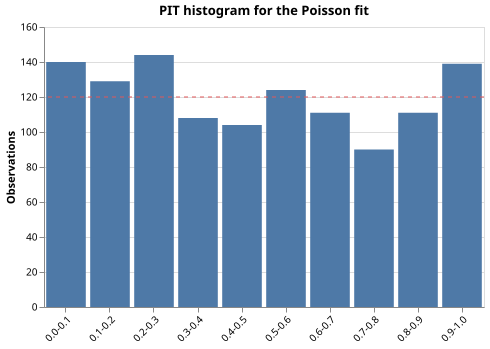

In [2]:
import altair as alt
# Plot the quantities interpreted in the following paragraph.
terms = "bbs(day, df=4) + bols(occupancy)"
poisson = mb.gamboostLSS({"mu": f"events ~ {terms}"}, data=data,
                         families=mb.PoissonLSS(),
                         control=mb.boost_control(200, 0.1))

pit = np.asarray(poisson.pit(random_state=0))
counts, _ = np.histogram(pit, bins=10, range=(0, 1))
expected = n / 10
chi_square = float(((counts - expected) ** 2 / expected).sum())
print(f"PIT histogram (10 bins, {expected:.0f} expected each): {counts}")
print(f"uniformity chi-square {chi_square:.1f} on 9 df "
      f"(5% critical value 16.9)")

pit_frame = pl.DataFrame({
    "bin": [f"{i / 10:.1f}-{(i + 1) / 10:.1f}" for i in range(10)],
    "count": counts,
})
bars = alt.Chart(pit_frame).mark_bar(color="#4e79a7").encode(
    x=alt.X("bin:N", title=None, axis=alt.Axis(labelAngle=-45)),
    y=alt.Y("count:Q", title="Observations"),
)
rule = alt.Chart(pl.DataFrame({"count": [expected]})).mark_rule(
    color="#e15759", strokeDash=[4, 4]).encode(y="count:Q")
(bars + rule).properties(
    title="PIT histogram for the Poisson fit",
    width=440, height=280)


## PIT diagnostic

The probability integral transform checks a fitted distribution against the
data. Applying the fitted distribution's own CDF to the observed responses
gives uniform values on (0, 1) under the true conditional distribution.
Here the CDF is estimated on the same rows, so the histogram and the 16.9
reference (the 5% critical value of a chi-square distribution with 9 degrees of freedom) are descriptive diagnostics rather than a calibrated 5% test.
Departures from uniformity can motivate checking the fitted specification
without requiring an alternative family to compare against. The response is discrete, so the transform is randomised, which
`pit()` does by default.

The histogram is heavy at both ends and thin in the middle: the end bins hold
140 and 139 against 120 expected, and the middle dips to 90. A U-shape of this
kind indicates a fitted distribution that is too narrow, with more observations
in the extreme tails than it allows for. That is overdispersion.

```{note}
The shape of the PIT histogram identifies the type of misfit. A U-shape means
the fitted distribution is too narrow, an inverted U that it is too wide, and a
slope that the location is systematically off. A single test statistic reports
only that something is wrong.
```


## Fitted effects under Poisson and negative binomial

Summary statistics compare the two families. The fitted seasonal
effect shows what changed when the family did.

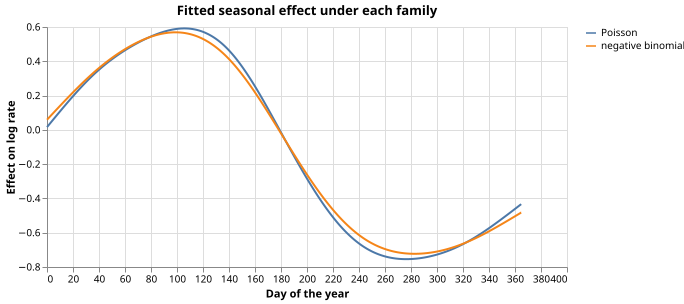

In [3]:
poisson_effects = poisson.partial_effects(parameter="mu")
negbin = mb.gamboostLSS({"mu": f"events ~ {terms}", "sigma": f"events ~ {terms}"},
                        data=data, families=mb.NBinomialLSS(),
                        control=mb.boost_control(200, 0.1))
negbin_effects = negbin.partial_effects(parameter="mu")

rows = []
for label, effects in (("Poisson", poisson_effects),
                       ("negative binomial", negbin_effects)):
    grid, effect = effects["day"]
    order = np.argsort(grid)
    rows.append(pl.DataFrame({"day": grid[order], "effect": effect[order],
                              "family": label}))
seasonal = pl.concat(rows)

alt.Chart(seasonal).mark_line(strokeWidth=2).encode(
    x=alt.X("day:Q", title="Day of the year"),
    y=alt.Y("effect:Q", title="Effect on log rate"),
    color=alt.Color("family:N", title=None),
).properties(title="Fitted seasonal effect under each family",
             width=520, height=240)

The two curves are close: the seasonal effect spans 1.63 on the log scale under
Poisson and 1.55 under the negative binomial. Changing the family changed the
fitted mean little.

The negative binomial also fits dispersion as a function of the same
predictors. This allows its variance to exceed its mean, whereas the Poisson
variance is fixed equal to the mean.

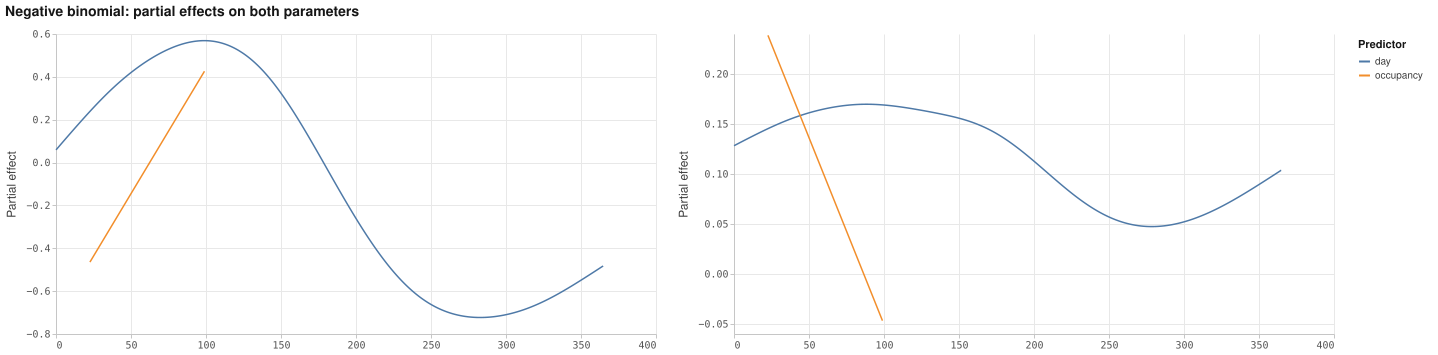

In [4]:
mb.plot.plot_lss(negbin).properties(
    title="Negative binomial: partial effects on both parameters")

Both parameters have a seasonal term, so the fitted distribution changes shape
across the year rather than only shifting. The negative binomial can represent
spread beyond the Poisson variance. The PIT assesses the fitted distribution
as a whole; it does not identify which predictor or parameter accounts for a
departure from uniformity.


## Extension: scanning the count families

The scan below fits each family appropriate to counts and ranks them by
out-of-bag risk, rather than selecting a replacement in advance.


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamlss.py:4320: RuntimeWarning: the lowest cross-validated risk is at [150], the largest budget in the grid, so the reported optimum is where the search stopped rather than where the risk turns. Extend the grid -- mb.diagonal_grid(300, 1) -- and refit with a control whose mstop covers it.
  return entry(folds=folds if isinstance(folds, FoldScheme) else folds_matrix,
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamlss.py:4320: RuntimeWarning: the lowest cross-validated risk is at [150, 150], the largest budget in the grid, so the reported optimum is where the search stopped rather than where the risk turns. Extend the grid -- mb.diagonal_grid(300, 2) -- and refit with a control whose mstop covers it.
  return entry(folds=folds if isinstance(folds, FoldScheme) else folds_matrix,


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamlss.py:4320: RuntimeWarning: the lowest cross-validated risk is at [150, 150, 150], the largest budget in the grid, so the reported optimum is where the search stopped rather than where the risk turns. Extend the grid -- mb.diagonal_grid(300, 3) -- and refit with a control whose mstop covers it.
  return entry(folds=folds if isinstance(folds, FoldScheme) else folds_matrix,


family,out-of-bag risk,in-sample risk
str,f64,f64
"""GeometricLSS""",1.0176,1217.6
"""NBinomialLSS""",1.0191,1217.2
"""NegativeBinomialLSS""",1.0217,1220.9
"""ZINBLSS""",1.0253,1225.7
"""ZeroAdjustedPoissonLSS""",1.0301,1227.4
"""ZIPoLSS""",1.038,1239.2
"""PoissonLSS""",1.0554,1260.1


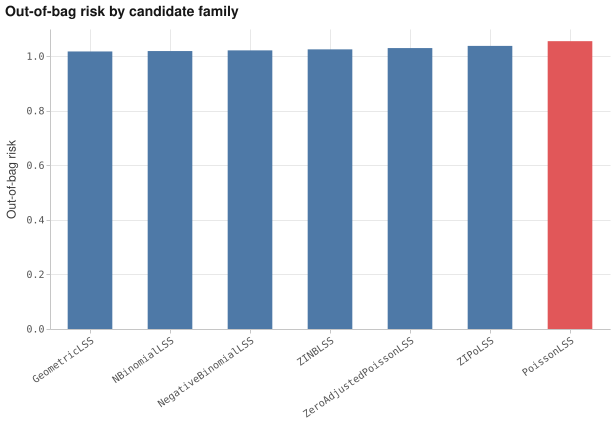

In [5]:
import altair as alt

specification = {"mu": f"events ~ {terms}", "sigma": f"events ~ {terms}"}
ranking = mb.scan_lss_families(specification, data=data, support="counts",
                               metric="cvrisk", fit_func="gamboostLSS",
                               control=mb.boost_control(150, 0.1))

ok = [r for r in ranking if r["status"] == "ok"]
display(pl.DataFrame([
    {"family": r["family"], "out-of-bag risk": round(r["cvrisk"], 4),
     "in-sample risk": round(r["risk"], 1)} for r in ok
]))

rank_frame = pl.DataFrame({
    "family": [r["family"] for r in ok],
    "cvrisk": [r["cvrisk"] for r in ok],
})
alt.Chart(rank_frame).mark_bar().encode(
    x=alt.X("family:N", title=None, sort="y", axis=alt.Axis(labelAngle=-35)),
    y=alt.Y("cvrisk:Q", title="Out-of-bag risk"),
    color=alt.condition(alt.datum.family == "PoissonLSS",
                        alt.value("#e15759"), alt.value("#4e79a7")),
).properties(
    title="Out-of-bag risk by candidate family",
    width=560, height=300)

Poisson ranks last, at 1.055 out-of-bag risk against 1.018 for the best family.

The ranking does not identify a single alternative. The top six families span
1.018 to 1.038, differences much smaller than the gap down to Poisson and small
enough that a different sample could reorder them.

These fitted comparisons favour alternatives to Poisson without identifying a unique replacement.
Reporting the top row as the best family would claim more than a 1200-day
sample supports.


## Extension: PIT across candidate families

Applying the same PIT check to each candidate shows where the additional
parameters help. The helper below fits a family, computes the randomised PIT,
and reports the chi-square of its histogram against the uniform expectation —
the same statistic used for the Poisson fit above.


In [6]:
def pit_uniformity(family, spec):
    fit = mb.gamboostLSS(spec, data=data, families=family,
                         control=mb.boost_control(200, 0.1))
    values = np.asarray(fit.pit(random_state=0))
    observed, _ = np.histogram(values, bins=10, range=(0, 1))
    return float(((observed - n / 10) ** 2 / (n / 10)).sum())


rows = [
    {"family": "PoissonLSS",
     "chi-square": round(pit_uniformity(mb.PoissonLSS(),
                                        {"mu": f"events ~ {terms}"}), 1)},
    {"family": "NBinomialLSS",
     "chi-square": round(pit_uniformity(mb.NBinomialLSS(), specification), 1)},
    {"family": "ZINBLSS",
     "chi-square": round(pit_uniformity(
         mb.ZINBLSS(), {**specification, "nu": f"events ~ {terms}"}), 1)},
]
display(pl.DataFrame(rows))
print("5% critical value on 9 df: 16.9")

family,chi-square
str,f64
"""PoissonLSS""",24.1
"""NBinomialLSS""",10.5
"""ZINBLSS""",17.2


5% critical value on 9 df: 16.9


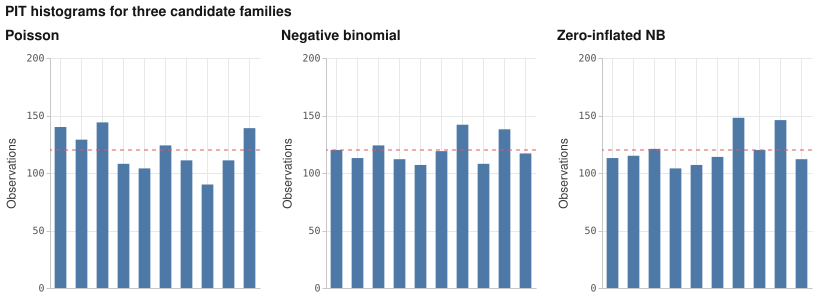

In [7]:
import altair as alt
# Plot the quantities interpreted in the following paragraph.
def pit_histogram(family, spec):
    fit = mb.gamboostLSS(spec, data=data, families=family,
                         control=mb.boost_control(200, 0.1))
    values = np.asarray(fit.pit(random_state=0))
    counts, _ = np.histogram(values, bins=10, range=(0, 1))
    return counts


candidates = [
    ("Poisson", mb.PoissonLSS(), {"mu": f"events ~ {terms}"}),
    ("Negative binomial", mb.NBinomialLSS(), specification),
    ("Zero-inflated NB", mb.ZINBLSS(),
     {**specification, "nu": f"events ~ {terms}"}),
]

charts = []
for label, family, spec in candidates:
    counts = pit_histogram(family, spec)
    frame = pl.DataFrame({
        "bin": [f"{i / 10:.1f}-{(i + 1) / 10:.1f}" for i in range(10)],
        "count": counts,
    })
    bars = alt.Chart(frame).mark_bar(color="#4e79a7").encode(
        x=alt.X("bin:N", title=None, axis=alt.Axis(labels=False, ticks=False)),
        y=alt.Y("count:Q", title="Observations",
                scale=alt.Scale(domain=[0, 200])),
    )
    rule = alt.Chart(pl.DataFrame({"count": [n / 10]})).mark_rule(
        color="#e15759", strokeDash=[4, 4]).encode(y="count:Q")
    charts.append((bars + rule).properties(title=label, width=210, height=230))

alt.hconcat(*charts).properties(
    title="PIT histograms for three candidate families")


The negative binomial's statistic is 10.5, below the 16.9 reference value.
Poisson scores 24.1. The zero-inflated negative binomial, which adds a third
parameter and contains the negative binomial as a special case, scores 51.8.
These are in-sample diagnostic comparisons, not calibrated rejection decisions.


## The generating process

The counts were drawn as a gamma-mixed Poisson, which is a negative binomial,
after which 18% of days were set to zero to represent days the ward did not
report. The true distribution is therefore a zero-inflated negative binomial —
the family with the worst diagnostic.

The poorer diagnostic for the three-parameter fit does not identify its
cause. This single sample compares fitted specifications at a fixed stopping
budget; it does not separate parameter-estimation error from the effects of
predictor specification or the fitting path. In particular, no uncertainty
estimate for the zero-inflation parameter is reported.

The comparison shows that fitting the generating family does not by itself
ensure a better PIT histogram under these settings.


## Conclusions

The response is overdispersed relative to Poisson. The PIT chi-square is 24.1
against the reference value of 16.9, and every candidate family has lower
out-of-bag risk than Poisson. The negative binomial's in-sample PIT statistic
is below the reference value, even though the known generating process
includes additional zero inflation. This does not establish its predictive
calibration on new ward-days.

The out-of-bag scores do not clearly distinguish the leading families. Six families sit within
about 2% of each other in out-of-bag risk, from 1.018 to 1.038, against a 4%
gap down to Poisson.

**A note on the criterion.** The scan ranks by out-of-bag risk rather than
GAIC. For a boosted fit, `df` is the number of selected base-learners, which
under cyclic fitting is `mstop * n_params + 1`, so GAIC penalises a family
partly for how many parameters it has, independent of fit. Ranking by GAIC here
would favour the one-parameter families for that reason rather than on
evidence.

The type of the response narrows the candidate families without choosing among
them. A distributional assumption is a hypothesis that can be checked: the PIT
compares it with the data directly, requires no alternative, and its shape
indicates the direction of the misfit. The interpretation of the top-ranked
family depends on the risk gap below it. This sample supports a class —
overdispersed relative to Poisson, with a negative binomial showing
less PIT departure under these settings — rather than a uniquely identified family.
